In [1]:
pip install pandas geopandas matplotlib

Note: you may need to restart the kernel to use updated packages.


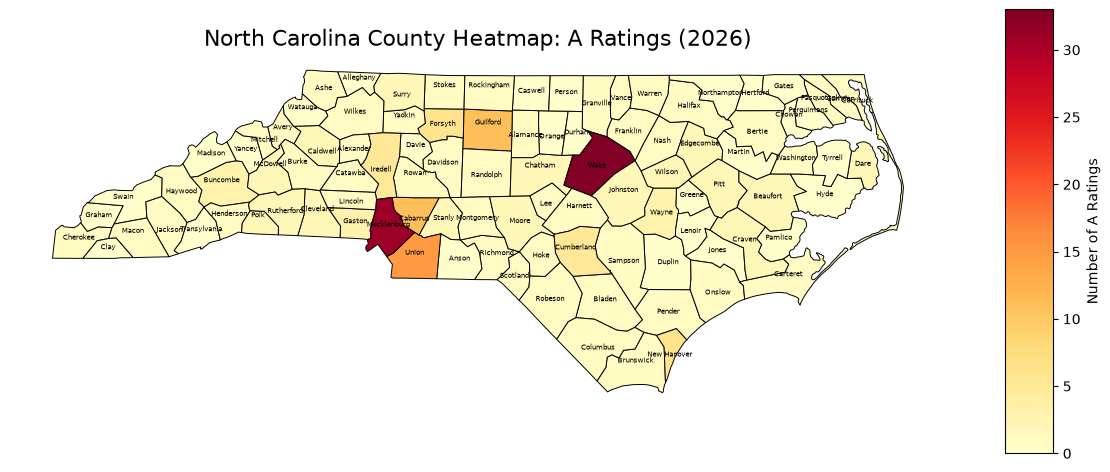

In [2]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

# Load the 2026 county data from Excel
df = pd.read_excel(r"C:\Users\Frank\school\UNCC\Fall2026\DTSC2302\countysheets.xlsx", sheet_name="2026county")

# Keep only the county name and gradeA columns
df = df[["NAME", "gradeA"]].copy()

# Remove "County" from county names for matching
df["NAME"] = df["NAME"].str.replace(" County", "", regex=False).str.strip()

# Load North Carolina county map boundaries
url = "https://raw.githubusercontent.com/plotly/datasets/master/geojson-counties-fips.json"
counties = gpd.read_file(url)

# Filter map to North Carolina (FIPS code 37)
nc_counties = counties[counties["STATE"] == "37"].copy()

# Match county names to the Excel data
map_data = nc_counties.merge(
    df,
    left_on="NAME",
    right_on="NAME",
    how="left"
)

# Create county heatmap
fig, ax = plt.subplots(figsize=(12, 10))

map_data.plot(
    column="gradeA",
    cmap="YlOrRd",
    linewidth=0.7,
    edgecolor="black",
    legend=True,
    legend_kwds={"label": "Number of A Ratings"},
    ax=ax
)

# Add county names
for idx, row in map_data.iterrows():
    point = row.geometry.representative_point()
    ax.annotate(
        text=row["NAME"],
        xy=(point.x, point.y),
        ha="center",
        fontsize=5
    )

# Format map
ax.set_title(
    "North Carolina County Heatmap: A Ratings (2026)",
    fontsize=16
)

ax.axis("off")
plt.tight_layout()
plt.show()

C:\Users\Frank\AppData\Local\Temp\ipykernel_21860\2077064138.py:107: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  county_data["DominantGrade"] = (
C:\Users\Frank\AppData\Local\Temp\ipykernel_21860\2077064138.py:132: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  county_data["county_key"] = (
c:\Users\Frank\anaconda3\Lib\site-packages\geopandas\geodataframe.py:2011: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining al

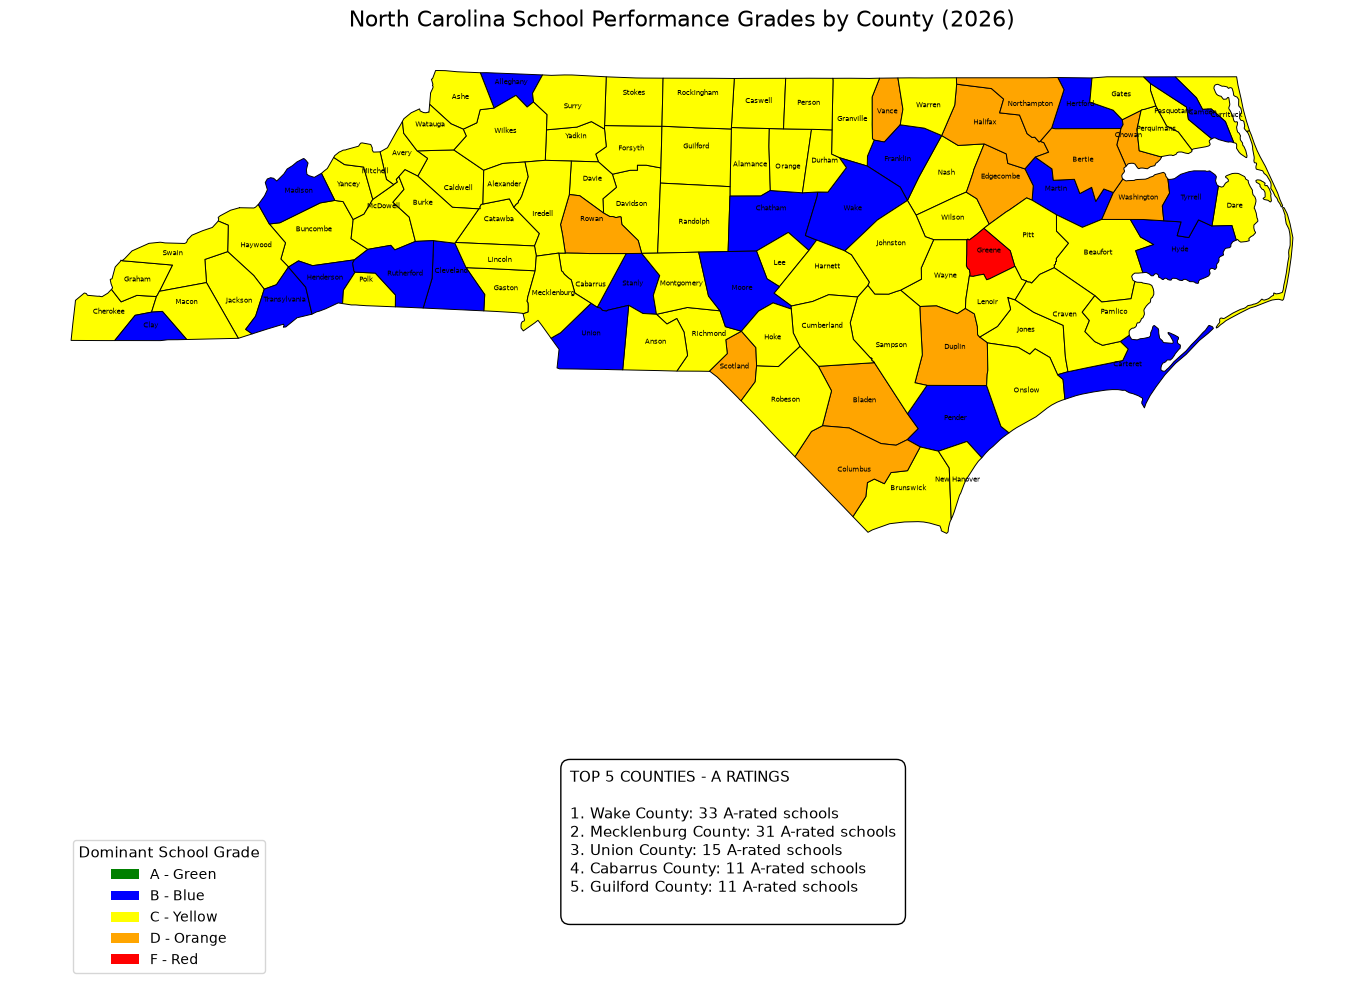

In [3]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import re

# -----------------------------------
# 1. Load county-level Excel data
# -----------------------------------

county_data = pd.read_excel(
    r"C:\Users\Frank\school\UNCC\Fall2026\DTSC2302\countysheets.xlsx",
    sheet_name="2026county"
)

# -----------------------------------
# 2. Load district-level CSV data
# -----------------------------------

district_data = pd.read_csv(
    r"C:\Users\Frank\Downloads\spg-state-2026.csv",
    skiprows=16
)

# Keep school district records
district_data = district_data[
    district_data["Kind"] == "district"
].copy()

# Convert grade columns to numeric
grade_columns = ["B", "C", "D", "F"]

for col in grade_columns:
    district_data[col] = pd.to_numeric(
        district_data[col],
        errors="coerce"
    ).fillna(0)

# -----------------------------------
# 3. Match districts to counties
# -----------------------------------

county_ratings = []

for county in county_data["NAME"]:

    # Remove County from county name
    county_name = re.sub(
        r"\s+County$",
        "",
        county,
        flags=re.IGNORECASE
    ).strip()

    # Find matching district
    pattern = rf"(?<![A-Za-z]){re.escape(county_name)}(?![A-Za-z])"

    matches = district_data[
        district_data["District"].str.contains(
            pattern,
            case=False,
            na=False,
            regex=True
        )
    ]

    if len(matches) == 1:

        row = matches.iloc[0]

        county_ratings.append({
            "NAME": county,
            "B": row["B"],
            "C": row["C"],
            "D": row["D"],
            "F": row["F"]
        })

    else:
        print(f"Check district match for {county}")

# Create DataFrame from matched districts
ratings_df = pd.DataFrame(county_ratings)

# Attach district ratings to county data
county_data = county_data.merge(
    ratings_df,
    on="NAME",
    how="left"
)

# -----------------------------------
# 4. Determine dominant grade
# -----------------------------------

# A comes from the county Excel file
# B, C, D, F come from the district CSV

county_data["gradeA"] = pd.to_numeric(
    county_data["gradeA"],
    errors="coerce"
).fillna(0)

grade_columns = ["gradeA", "B", "C", "D", "F"]

# Find the grade with the highest count
county_data["DominantGrade"] = (
    county_data[grade_columns]
    .idxmax(axis=1)
    .str.replace("gradeA", "A")
)

# -----------------------------------
# 5. Load North Carolina map
# -----------------------------------

url = (
    "https://raw.githubusercontent.com/"
    "plotly/datasets/master/geojson-counties-fips.json"
)

counties = gpd.read_file(url)

# Select North Carolina counties
nc_counties = counties[
    counties["STATE"] == "37"
].copy()

# Prepare matching county names
nc_counties["county_key"] = nc_counties["NAME"]

county_data["county_key"] = (
    county_data["NAME"]
    .str.replace(" County", "", regex=False)
    .str.strip()
)

# Merge county ratings with map boundaries
map_data = nc_counties.merge(
    county_data,
    on="county_key",
    how="left"
)

# -----------------------------------
# 6. Assign colors to grades
# -----------------------------------

grade_colors = {
    "A": "green",
    "B": "blue",
    "C": "yellow",
    "D": "orange",
    "F": "red"
}

map_data["MapColor"] = (
    map_data["DominantGrade"].map(grade_colors)
)

# -----------------------------------
# 7. Create North Carolina map
# -----------------------------------

fig, ax = plt.subplots(figsize=(14, 12))

map_data.plot(
    color=map_data["MapColor"],
    edgecolor="black",
    linewidth=0.7,
    ax=ax
)

# Add county names
for idx, row in map_data.iterrows():

    point = row.geometry.representative_point()

    ax.annotate(
        text=row["NAME_x"],
        xy=(point.x, point.y),
        ha="center",
        fontsize=5
    )

# -----------------------------------
# 8. Create color key
# -----------------------------------

legend_items = [
    Patch(facecolor="green", label="A - Green"),
    Patch(facecolor="blue", label="B - Blue"),
    Patch(facecolor="yellow", label="C - Yellow"),
    Patch(facecolor="orange", label="D - Orange"),
    Patch(facecolor="red", label="F - Red")
]

# Move key to bottom left
fig.legend(
    handles=legend_items,
    title="Dominant School Grade",
    loc="lower left",
    bbox_to_anchor=(0.06, 0.025),
    fontsize=10,
    title_fontsize=11
)

# -----------------------------------
# 9. Find five counties with most A's
# -----------------------------------

top_five = (
    county_data
    .nlargest(5, "gradeA")[["NAME", "gradeA"]]
)

# Create text for top five counties
top_five_text = "TOP 5 COUNTIES - A RATINGS\n\n"

for rank, (_, row) in enumerate(top_five.iterrows(), start=1):
    top_five_text += (
        f"{rank}. {row['NAME']}: "
        f"{int(row['gradeA'])} A-rated schools\n"
    )

# Place top five section to the right of the key
fig.text(
    0.42,
    0.14,
    top_five_text,
    fontsize=11,
    verticalalignment="center",
    bbox=dict(
        boxstyle="round,pad=0.6",
        facecolor="white",
        edgecolor="black"
    )
)

# -----------------------------------
# 10. Format visualization
# -----------------------------------

ax.set_title(
    "North Carolina School Performance Grades by County (2026)",
    fontsize=16,
    pad=15
)

ax.axis("off")

# Leave room below map for key and top five list
ax.set_position([0.02, 0.24, 0.96, 0.70])

plt.show()


C:\Users\Frank\AppData\Local\Temp\ipykernel_21860\4230325546.py:107: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  county_data["DominantGrade"] = (
C:\Users\Frank\AppData\Local\Temp\ipykernel_21860\4230325546.py:132: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  county_data["county_key"] = (
c:\Users\Frank\anaconda3\Lib\site-packages\geopandas\geodataframe.py:2011: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining al

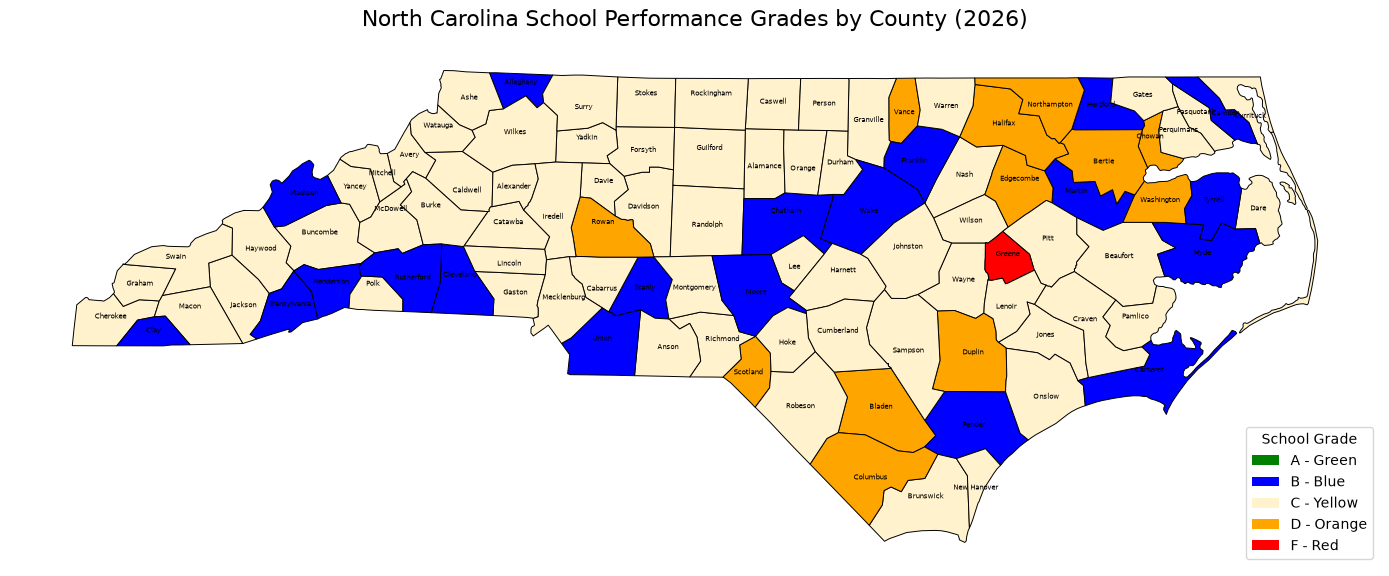

In [4]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import re

# -----------------------------------
# 1. Load county-level Excel data
# -----------------------------------

county_data = pd.read_excel(
    r"C:\Users\Frank\school\UNCC\Fall2026\DTSC2302\countysheets.xlsx",
    sheet_name="2026county"
)

# -----------------------------------
# 2. Load district-level CSV data
# -----------------------------------

district_data = pd.read_csv(
    r"C:\Users\Frank\Downloads\spg-state-2026.csv",
    skiprows=16
)

# Keep school district records
district_data = district_data[
    district_data["Kind"] == "district"
].copy()

# Convert grade columns to numeric
grade_columns = ["B", "C", "D", "F"]

for col in grade_columns:
    district_data[col] = pd.to_numeric(
        district_data[col],
        errors="coerce"
    ).fillna(0)

# -----------------------------------
# 3. Match districts to counties
# -----------------------------------

county_ratings = []

for county in county_data["NAME"]:

    # Remove County from county name
    county_name = re.sub(
        r"\s+County$",
        "",
        county,
        flags=re.IGNORECASE
    ).strip()

    # Find matching district
    pattern = rf"(?<![A-Za-z]){re.escape(county_name)}(?![A-Za-z])"

    matches = district_data[
        district_data["District"].str.contains(
            pattern,
            case=False,
            na=False,
            regex=True
        )
    ]

    if len(matches) == 1:

        row = matches.iloc[0]

        county_ratings.append({
            "NAME": county,
            "B": row["B"],
            "C": row["C"],
            "D": row["D"],
            "F": row["F"]
        })

    else:
        print(f"Check district match for {county}")

# Create DataFrame from matched districts
ratings_df = pd.DataFrame(county_ratings)

# Attach district ratings to county data
county_data = county_data.merge(
    ratings_df,
    on="NAME",
    how="left"
)

# -----------------------------------
# 4. Determine dominant grade
# -----------------------------------

# A comes from the county Excel file
# B, C, D, F come from the district CSV

county_data["gradeA"] = pd.to_numeric(
    county_data["gradeA"],
    errors="coerce"
).fillna(0)

grade_columns = ["gradeA", "B", "C", "D", "F"]

# Find the grade with the highest count
county_data["DominantGrade"] = (
    county_data[grade_columns]
    .idxmax(axis=1)
    .str.replace("gradeA", "A")
)

# -----------------------------------
# 5. Load North Carolina map
# -----------------------------------

url = (
    "https://raw.githubusercontent.com/"
    "plotly/datasets/master/geojson-counties-fips.json"
)

counties = gpd.read_file(url)

# Select North Carolina counties
nc_counties = counties[
    counties["STATE"] == "37"
].copy()

# Prepare matching county names
nc_counties["county_key"] = nc_counties["NAME"]

county_data["county_key"] = (
    county_data["NAME"]
    .str.replace(" County", "", regex=False)
    .str.strip()
)

# Merge county ratings with map boundaries
map_data = nc_counties.merge(
    county_data,
    on="county_key",
    how="left"
)

# -----------------------------------
# 6. Assign colors to grades
# -----------------------------------

grade_colors = {
    "A": "green",
    "B": "blue",
    "C": "#FFF2CC",
    "D": "orange",
    "F": "red"
}

map_data["MapColor"] = (
    map_data["DominantGrade"].map(grade_colors)
)

# -----------------------------------
# 7. Create one county heatmap
# -----------------------------------

fig, ax = plt.subplots(figsize=(14, 11))

map_data.plot(
    color=map_data["MapColor"],
    edgecolor="black",
    linewidth=0.7,
    ax=ax
)

# Add county names
for idx, row in map_data.iterrows():

    point = row.geometry.representative_point()

    ax.annotate(
        text=row["NAME_x"],
        xy=(point.x, point.y),
        ha="center",
        fontsize=5
    )

# -----------------------------------
# 8. Create legend
# -----------------------------------

legend_items = [
    Patch(facecolor="green", label="A - Green"),
    Patch(facecolor="blue", label="B - Blue"),
    Patch(facecolor="#FFF2CC", label="C - Yellow"),
    Patch(facecolor="orange", label="D - Orange"),
    Patch(facecolor="red", label="F - Red")
]

ax.legend(
    handles=legend_items,
    title="School Grade",
    loc="lower right"
)

# -----------------------------------
# 9. Format map
# -----------------------------------

ax.set_title(
    "North Carolina School Performance Grades by County (2026)",
    fontsize=16,
    pad=15
)

ax.axis("off")

plt.tight_layout()
plt.show()